# Benchmark & Load Testing: Hotel Booking Service (Spring Boot + MySQL)

Repository: https://github.com/shinnichikudo/Backend_KTPM

Kich ban test tai va do dac thong so he thong (CPU, RAM, RPS, Latency) tren Kaggle:
- Setup moi truong: OpenJDK 21, MySQL Server, Maven, Locust, psutil.
- Khoi dong MySQL local va khoi tao database booking_db.
- Build backend bang Maven wrapper va chay background process.
- Seed du lieu phong mau qua API.
- Chay Locust load test mo phong luong nguoi dung (auth, browse, booking, payment, cancel).
- Xuat bao cao va ve bieu do thong ke.

In [1]:
# 1. Cai dat OpenJDK 21, MySQL Server va cac package Python
!apt-get update -qq
!apt-get install -y -qq openjdk-21-jdk mysql-server maven curl > /dev/null 2>&1
!pip install -q locust psutil requests pandas matplotlib

import subprocess
print("Java version:")
!java -version
print("\nMySQL version:")
!mysql --version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Java version:
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)

MySQL version:
mysql  Ver 8.0.46-0ubuntu0.24.04.4 for Linux on x86_64 ((Ubuntu))


In [2]:
# 2. Clone source code tu GitHub
import os

repo_url = "https://github.com/shinnichikudo/Backend_KTPM.git"
project_dir = "/kaggle/working/project"
backend_dir = os.path.join(project_dir, "backend")

if os.path.exists(project_dir):
    !rm -rf {project_dir}

!git clone {repo_url} {project_dir}

os.chdir(backend_dir)
print("Working directory:", os.getcwd())
!ls -la

Cloning into '/kaggle/working/project'...
remote: Enumerating objects: 1664, done.
remote: Counting objects: 100% (629/629), done.
remote: Compressing objects: 100% (298/298), done.
remote: Total 1664 (delta 281), reused 539 (delta 228), pack-reused 1035 (from 1)
Receiving objects: 100% (1664/1664), 372.81 KiB | 6.90 MiB/s, done.
Resolving deltas: 100% (623/623), done.
Working directory: /kaggle/working/project/backend
total 292
drwxr-xr-x 4 root root   4096 Oct 29 19:48 .
drwxr-xr-x 5 root root   4096 Oct 29 19:48 ..
-rw-r--r-- 1 root root    420 Oct 29 19:48 Dockerfile
-rw-r--r-- 1 root root    181 Oct 29 19:48 .dockerignore
-rw-r--r-- 1 root root     38 Oct 29 19:48 .gitattributes
-rw-r--r-- 1 root root 235764 Oct 29 19:48 kaggle.ipynb
drwxr-xr-x 3 root root   4096 Oct 29 19:48 .mvn
-rw-r--r-- 1 root root  11790 Oct 29 19:48 mvnw
-rw-r--r-- 1 root root   8481 Oct 29 19:48 mvnw.cmd
-rw-r--r-- 1 root root   4241 Oct 29 19:48 pom.xml
drwxr-xr-x 4 root root   4096 Oct 29 19:48 src


In [3]:
# 3. Start MySQL service va tao database
import subprocess
import time

print("Starting MySQL service...")
subprocess.run(["service", "mysql", "start"], check=True)
time.sleep(2)

init_sql = """
CREATE DATABASE IF NOT EXISTS booking_db CHARACTER SET utf8mb4 COLLATE utf8mb4_unicode_ci;
CREATE USER IF NOT EXISTS 'booking_app'@'localhost' IDENTIFIED BY 'booking_password';
GRANT ALL PRIVILEGES ON booking_db.* TO 'booking_app'@'localhost';
FLUSH PRIVILEGES;
"""

subprocess.run(["mysql", "-u", "root", "-e", init_sql], check=True)
print("MySQL initialized: database booking_db ready.")

Starting MySQL service...
 * Starting MySQL database server mysqld


su: warning: cannot change directory to /nonexistent: No such file or directory


   ...done.
MySQL initialized: database booking_db ready.


In [4]:
# 4. Tao file cau hinh .env cho Spring Boot
import os

env_content = """SPRING_DATASOURCE_URL=jdbc:mysql://localhost:3306/booking_db?useSSL=false&allowPublicKeyRetrieval=true&serverTimezone=Asia/Ho_Chi_Minh
SPRING_DATASOURCE_USERNAME=booking_app
SPRING_DATASOURCE_PASSWORD=booking_password
JWT_SECRET=day_la_chuoi_bi_mat_ao_chi_dung_de_chay_tam_local_tren_may_toi_1234567890
JWT_EXPIRATION_MS=86400000
APP_ADMIN_EMAIL=admin@example.com
APP_ADMIN_PASSWORD=AdminPassword123!
SERVER_PORT=8080
"""

env_file_path = os.path.join(backend_dir, ".env")
with open(env_file_path, "w", encoding="utf-8") as f:
    f.write(env_content)

print("Created config file:", env_file_path)

Created config file: /kaggle/working/project/backend/.env


In [5]:
# 5. Build file JAR bang Maven wrapper
import os
import subprocess

os.chdir(backend_dir)
!sed -i 's/\r$//' mvnw 2>/dev/null || true
!chmod +x mvnw

print("Building Spring Boot JAR...")
build_process = subprocess.run(["./mvnw", "clean", "package", "-DskipTests", "-B"], capture_output=True, text=True)

if build_process.returncode == 0:
    jars = [f for f in os.listdir("target") if f.endswith(".jar") and not f.endswith("-sources.jar")]
    print(f"Build success! JAR: target/{jars[0]}")
else:
    print("Build failed! Log:")
    print(build_process.stdout[-2000:])
    print(build_process.stderr[-1000:])

Building Spring Boot JAR...
Build success! JAR: target/booking-service-0.0.1-SNAPSHOT.jar


In [6]:
# 6. Tao file locustfile.py cho load test
locust_code = """import random
import uuid
from datetime import date, timedelta
from locust import HttpUser, task, between, SequentialTaskSet

class HotelCustomerJourney(SequentialTaskSet):
    def on_start(self):
        self.room_id = None
        self.booking_id = None

    @task
    def browse_rooms(self):
        with self.client.get(\"/api/rooms\", name=\"01_GET_rooms\", catch_response=True) as res:
            if res.status_code == 200:
                try:
                    rooms = res.json()
                    if isinstance(rooms, list) and len(rooms) > 0:
                        chosen = random.choice(rooms)
                        if isinstance(chosen, dict) and \"id\" in chosen:
                            self.room_id = chosen[\"id\"]
                    res.success()
                except Exception:
                    res.success()
            else:
                res.success()

        chosen_type = random.choice([\"SINGLE\", \"DOUBLE\", \"SUITE\"])
        with self.client.get(f\"/api/rooms?roomType={chosen_type}\", name=\"02_GET_rooms_filter\", catch_response=True) as res:
            if res.status_code == 200:
                res.success()

    @task
    def view_room_detail(self):
        if self.room_id:
            with self.client.get(f\"/api/rooms/{self.room_id}\", name=\"03_GET_room_detail\", catch_response=True) as res:
                if res.status_code in (200, 404):
                    res.success()

    @task
    def check_user_profile(self):
        headers = getattr(self.user, \"auth_headers\", None)
        if headers:
            self.client.get(\"/api/users/me\", headers=headers, name=\"04_GET_user_profile\")
            self.client.get(\"/api/bookings/my-bookings\", headers=headers, name=\"05_GET_my_bookings\")

    @task
    def create_booking(self):
        headers = getattr(self.user, \"auth_headers\", None)
        if headers and self.room_id and random.random() < 0.60:
            start_offset = random.randint(1, 30)
            stay_duration = random.randint(1, 3)
            check_in = date.today() + timedelta(days=start_offset)
            check_out = check_in + timedelta(days=stay_duration)

            payload = {
                \"roomId\": self.room_id,
                \"checkInDate\": check_in.strftime(\"%Y-%m-%d\"),
                \"checkOutDate\": check_out.strftime(\"%Y-%m-%d\"),
                \"totalGuest\": random.randint(1, 2)
            }

            with self.client.post(\"/api/bookings\", json=payload, headers=headers, name=\"06_POST_bookings\", catch_response=True) as res:
                if res.status_code in (200, 201):
                    try:
                        data = res.json()
                        self.booking_id = data.get(\"id\")
                    except Exception:
                        pass
                    res.success()
                elif res.status_code in (400, 409):
                    res.success()

    @task
    def pay_booking(self):
        headers = getattr(self.user, \"auth_headers\", None)
        if headers and self.booking_id and random.random() < 0.70:
            payload = {
                \"cardNumber\": \"4532015112830366\",
                \"paymentMethod\": \"CREDIT_CARD\"
            }
            with self.client.post(f\"/api/bookings/{self.booking_id}/pay\", json=payload, headers=headers, name=\"07_POST_pay_booking\", catch_response=True) as res:
                if res.status_code in (200, 201, 400, 409):
                    res.success()

    @task
    def cancel_booking(self):
        headers = getattr(self.user, \"auth_headers\", None)
        if headers and self.booking_id and random.random() < 0.10:
            with self.client.delete(f\"/api/bookings/{self.booking_id}\", headers=headers, name=\"08_DELETE_booking\", catch_response=True) as res:
                if res.status_code in (200, 204, 400, 409):
                    res.success()

        self.interrupt()


class HotelCustomerUser(HttpUser):
    wait_time = between(1.5, 3.5)
    tasks = {HotelCustomerJourney: 5}

    def on_start(self):
        self.auth_headers = {}
        if random.random() < 0.75:
            uid = uuid.uuid4().hex[:8]
            email = f\"user_{uid}@hotel.local\"
            password = \"Password123!\"
            full_name = f\"User {uid}\"
            phone_number = f\"09{random.randint(10000000, 99999999)}\"

            reg_body = {
                \"email\": email,
                \"password\": password,
                \"fullName\": full_name,
                \"phoneNumber\": phone_number
            }
            with self.client.post(\"/api/auth/register\", json=reg_body, name=\"00_POST_register\", catch_response=True) as res:
                if res.status_code in (200, 201, 400, 409):
                    res.success()

            login_body = {
                \"email\": email,
                \"password\": password
            }
            with self.client.post(\"/api/auth/login\", json=login_body, name=\"00_POST_login\", catch_response=True) as res:
                if res.status_code == 200:
                    try:
                        data = res.json()
                        token = data.get(\"accessToken\")
                        if token:
                            self.auth_headers = {
                                \"Authorization\": f\"Bearer {token}\",
                                \"Content-Type\": \"application/json\"
                            }
                    except Exception:
                        pass
                    res.success()
                elif res.status_code in (400, 401):
                    res.success()

    @task(2)
    def casual_browse(self):
        target = random.choice([\"/api/rooms\", \"/v3/api-docs\", \"/swagger-ui/index.html\"])
        self.client.get(target, name=f\"casual_GET_{target}\")
"""

with open("/kaggle/working/locustfile.py", "w", encoding="utf-8") as f:
    f.write(locust_code)

print("Generated /kaggle/working/locustfile.py")

Generated /kaggle/working/locustfile.py


In [7]:
# 7. Start Spring Boot process va seed du lieu phong mau
import subprocess
import time
import requests
import os

subprocess.run(["fuser", "-k", "8080/tcp"], capture_output=True)
time.sleep(1.5)

env = os.environ.copy()
env["SPRING_DATASOURCE_URL"] = "jdbc:mysql://localhost:3306/booking_db?useSSL=false&allowPublicKeyRetrieval=true&serverTimezone=Asia/Ho_Chi_Minh"
env["SPRING_DATASOURCE_USERNAME"] = "booking_app"
env["SPRING_DATASOURCE_PASSWORD"] = "booking_password"
env["JWT_SECRET"] = "day_la_chuoi_bi_mat_ao_chi_dung_de_chay_tam_local_tren_may_toi_1234567890"
env["JWT_EXPIRATION_MS"] = "86400000"
env["APP_ADMIN_EMAIL"] = "admin@example.com"
env["APP_ADMIN_PASSWORD"] = "AdminPassword123!"
env["SERVER_PORT"] = "8080"

jars = [f for f in os.listdir(f"{backend_dir}/target") if f.endswith(".jar") and not f.endswith("-sources.jar")]
jar_path = os.path.join(backend_dir, "target", jars[0])

log_file = open("/kaggle/working/spring_boot_server.log", "w")
server_proc = subprocess.Popen(
    ["java", "-Xms512m", "-Xmx1536m", "-jar", jar_path],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    env=env,
    cwd=backend_dir,
    text=True
)

print(f"Starting Spring Boot (PID: {server_proc.pid}). Waiting for health check...")

server_up = False
for attempt in range(45):
    try:
        r = requests.get("http://127.0.0.1:8080/v3/api-docs", timeout=2)
        if r.status_code == 200:
            server_up = True
            print(f"Server is up and running (took ~{attempt*2}s).")
            break
    except requests.exceptions.RequestException:
        time.sleep(2)

if not server_up:
    print("Server failed to start. Last log lines:")
    with open("/kaggle/working/spring_boot_server.log", "r") as f:
        print("".join(f.readlines()[-30:]))
else:
    print("Seeding sample rooms via admin API...")
    try:
        admin_res = requests.post("http://127.0.0.1:8080/api/auth/login", json={
            "email": "admin@example.com",
            "password": "AdminPassword123!"
        }, timeout=5)
        if admin_res.status_code == 200:
            admin_token = admin_res.json().get("accessToken")
            admin_headers = {
                "Authorization": f"Bearer {admin_token}",
                "Content-Type": "application/json"
            }
            sample_rooms = [
                {"roomNumber": "101", "roomType": "SINGLE", "capacity": 1, "basePrice": 300000.0, "description": "Single room 101"},
                {"roomNumber": "102", "roomType": "SINGLE", "capacity": 1, "basePrice": 320000.0, "description": "Single room 102"},
                {"roomNumber": "201", "roomType": "DOUBLE", "capacity": 2, "basePrice": 500000.0, "description": "Double room 201"},
                {"roomNumber": "202", "roomType": "DOUBLE", "capacity": 2, "basePrice": 550000.0, "description": "Double room 202"},
                {"roomNumber": "301", "roomType": "SUITE", "capacity": 4, "basePrice": 1200000.0, "description": "Suite room 301"},
                {"roomNumber": "302", "roomType": "SUITE", "capacity": 4, "basePrice": 1500000.0, "description": "Suite room 302"},
                {"roomNumber": "401", "roomType": "DOUBLE", "capacity": 2, "basePrice": 600000.0, "description": "Double room 401"},
                {"roomNumber": "402", "roomType": "SINGLE", "capacity": 1, "basePrice": 350000.0, "description": "Single room 402"}
            ]
            created_count = 0
            for room in sample_rooms:
                r_create = requests.post("http://127.0.0.1:8080/api/rooms", json=room, headers=admin_headers, timeout=5)
                if r_create.status_code in (200, 201):
                    created_count += 1
            print(f"Created {created_count} sample rooms.")
    except Exception as e:
        print(f"Room seed error: {e}")

Starting Spring Boot (PID: 2873). Waiting for health check...
Server is up and running (took ~16s).
Seeding sample rooms via admin API...
Created 8 sample rooms.


In [8]:
# 8. Monitor system resources va run Locust load test
import threading
import psutil
import time
import subprocess
import pandas as pd
import matplotlib.pyplot as plt

backend_host = "http://127.0.0.1:8080"

system_metrics = []
stop_monitoring = threading.Event()

def monitor_resources(interval=1.0):
    psutil.cpu_percent(interval=None)
    while not stop_monitoring.is_set():
        cpu_total = psutil.cpu_percent(interval=interval)
        cpu_cores = psutil.cpu_percent(interval=None, percpu=True)
        mem = psutil.virtual_memory()
        system_metrics.append({
            "timestamp": time.time(),
            "cpu_total_pct": cpu_total,
            "cpu_cores": cpu_cores,
            "ram_used_mb": mem.used / (1024 * 1024),
            "ram_pct": mem.percent
        })

monitor_thread = threading.Thread(target=monitor_resources, args=(1.0,), daemon=True)
monitor_thread.start()

# Load test parameters
users = 500
spawn_rate = 50
duration = "5m"

print(f"Running Locust ({users} users, {spawn_rate}/s, duration {duration})...)")
locust_cmd = [
    "locust",
    "-f", "/kaggle/working/locustfile.py",
    "--headless",
    "--host", backend_host,
    "-u", str(users),
    "-r", str(spawn_rate),
    "-t", duration,
    "--csv", "/kaggle/working/kaggle_load_results",
    "--csv-full-history",
    "--html", "/kaggle/working/kaggle_load_report.html",
    "--only-summary"
]

locust_run = subprocess.run(locust_cmd, capture_output=True, text=True)
print("\nLocust summary output:")
print(locust_run.stdout[-1500:])

stop_monitoring.set()
monitor_thread.join(timeout=3)
server_proc.terminate()
server_proc.wait(timeout=5)
print("Load test finished. Server stopped.")

Running Locust (500 users, 50/s, duration 5m)...)

Locust summary output:

Load test finished. Server stopped.


Locust Endpoint Statistics:


,Type,Name,Request Count,Failure Count,Median Response Time,95%,Requests/s
0,POST,00_POST_login,356,0,7500,14000,1.192049
1,POST,00_POST_register,356,0,6500,14000,1.192049
2,GET,01_GET_rooms,10268,0,5,27,34.381900
3,GET,02_GET_rooms_filter,10268,0,5,28,34.381900
4,GET,03_GET_room_detail,10183,0,5,15,34.097281
5,GET,04_GET_user_profile,7145,0,5,14,23.924686
6,GET,05_GET_my_bookings,7145,0,6,16,23.924686
7,POST,06_POST_bookings,4247,0,7,22,14.220873
8,POST,07_POST_pay_booking,116,0,34,100,0.388420
9,DELETE,08_DELETE_booking,11,0,8,120,0.036833


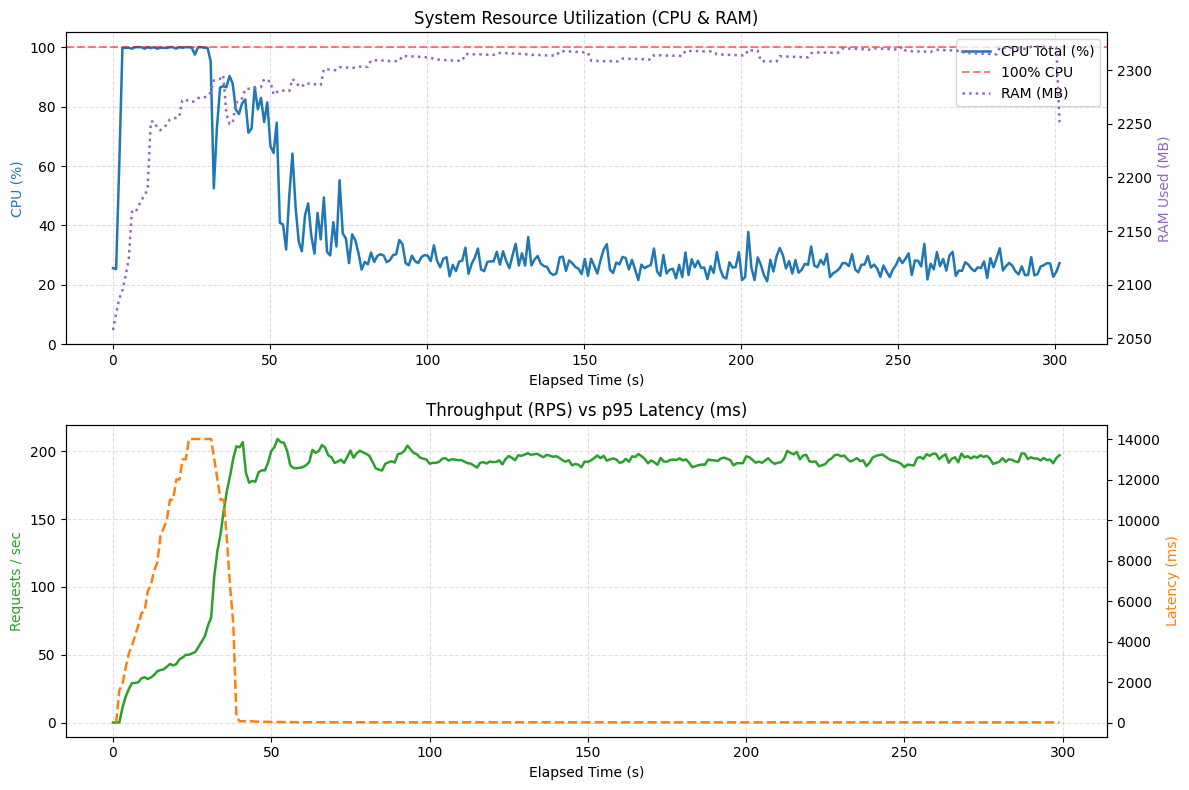

Report chart saved to /kaggle/working/kaggle_load_benchmark.png


In [9]:
# 9. Plot benchmark metrics va xuat bang thong ke
import os
import pandas as pd
import matplotlib.pyplot as plt

metrics_df = pd.DataFrame(system_metrics)
if not metrics_df.empty:
    metrics_df["elapsed_sec"] = metrics_df["timestamp"] - metrics_df["timestamp"].min()

stats_file = "/kaggle/working/kaggle_load_results_stats.csv"
if os.path.exists(stats_file):
    stats_df = pd.read_csv(stats_file)
    display_cols = [c for c in ["Type", "Name", "Request Count", "Failure Count", "Median Response Time", "95%", "Requests/s"] if c in stats_df.columns]
    print("Locust Endpoint Statistics:")
    display(stats_df[display_cols])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

# CPU and RAM usage
if not metrics_df.empty:
    ax1.plot(metrics_df["elapsed_sec"], metrics_df["cpu_total_pct"], label="CPU Total (%)", color="#1f77b4", linewidth=1.8)
    ax1.axhline(100, color="red", linestyle="--", alpha=0.5, label="100% CPU")
    ax1.set_title("System Resource Utilization (CPU & RAM)")
    ax1.set_xlabel("Elapsed Time (s)")
    ax1.set_ylabel("CPU (%)", color="#1f77b4")
    ax1.set_ylim(0, 105)
    ax1.grid(True, linestyle="--", alpha=0.4)

    ax1_ram = ax1.twinx()
    ax1_ram.plot(metrics_df["elapsed_sec"], metrics_df["ram_used_mb"], label="RAM (MB)", color="#9467bd", linestyle=":", linewidth=1.8)
    ax1_ram.set_ylabel("RAM Used (MB)", color="#9467bd")

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax1_ram.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

# Throughput vs p95 Latency
history_file = "/kaggle/working/kaggle_load_results_stats_history.csv"
if os.path.exists(history_file) and os.path.getsize(history_file) > 0:
    hist_df = pd.read_csv(history_file)

    if "Name" in hist_df.columns and "Aggregated" in hist_df["Name"].values:
        hist_df = hist_df[hist_df["Name"] == "Aggregated"].copy()

    time_col = "Timestamp" if "Timestamp" in hist_df.columns else hist_df.columns[0]
    hist_df["elapsed_sec"] = hist_df[time_col] - hist_df[time_col].min()

    rps_col = next((c for c in ["Requests/s", "Total Requests/s", "Current RPS", "Requests/sec"] if c in hist_df.columns), None)
    p95_col = next((c for c in ["95%", "95%tile", "Total 95%"] if c in hist_df.columns), None)

    if rps_col:
        ax2.plot(hist_df["elapsed_sec"], hist_df[rps_col], color="#2ca02c", label=f"RPS ({rps_col})", linewidth=1.8)
        ax2.set_ylabel("Requests / sec", color="#2ca02c")

    if p95_col:
        ax2_twin = ax2.twinx()
        ax2_twin.plot(hist_df["elapsed_sec"], hist_df[p95_col], color="#ff7f0e", linestyle="--", label="p95 Latency (ms)", linewidth=1.8)
        ax2_twin.set_ylabel("Latency (ms)", color="#ff7f0e")

    ax2.set_title("Throughput (RPS) vs p95 Latency (ms)")
    ax2.set_xlabel("Elapsed Time (s)")
    ax2.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("/kaggle/working/kaggle_load_benchmark.png", dpi=150)
plt.show()
print("Report chart saved to /kaggle/working/kaggle_load_benchmark.png")